# Decisions 2 and 3: look at the evidence, then decide

Both decisions are about the **truth** that every variance forecast will be compared with.

- **Decision 2:** which hours should the true variance cover?
- **Decision 3:** what to do on the 459 days when a company reported right after the close?

Each part shows the numbers and a chart, says what to look for, and ends with the options.
Nothing in this notebook changes your data or your settings.

**How to use it.** The results are already filled in, so you can simply read from top to bottom.
To change something (another stock, another period), edit the cell and run all cells from the top.
Running needs one install first: `pip install ipykernel`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from thesis.paths import PANEL, load_config

cfg = load_config()
panel = pd.read_parquet(PANEL).sort_values(["symbol", "date"]).reset_index(drop=True)
print(f"{len(panel):,} rows = {panel.symbol.nunique()} stocks x {panel.date.nunique():,} days, "
      f"{panel.date.min().date()} to {panel.date.max().date()}")
print("current settings in config.yaml:", cfg["target"])

# chart style: three colours checked for colour-blind safety, quiet grid, dark text
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "figure.dpi": 110,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})


def tidy(ax, title, subtitle=None):
    ax.set_title(title, loc="left", color=INK, fontsize=11.5, fontweight="bold", pad=26 if subtitle else 8)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8), textcoords="offset points",
                    color=MUTED, fontsize=9.5)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

117,280 rows = 40 stocks x 2,932 days, 2015-01-02 to 2026-08-31
current settings in config.yaml: {'intraday_measure': 'rv5_ss', 'add_overnight': True, 'earnings_days': 'flag_only', 'log_target': True}


---
## Decision 2: which hours does the true variance cover?

VOLARE's `rv5_ss` adds up squared five-minute returns while the market is open, 09:30 to 16:05.
Your models forecast the variance of the **close-to-close** return, which also contains the move
from yesterday's close to today's open.

- **Option (a):** truth = `rv5_ss` + squared overnight return. Same 24 hours as the forecast.
- **Option (b):** truth = `rv5_ss` only. Trading hours.

### Check 1: does the truth have the same size as what the models forecast?

Over a long sample, the average squared daily return and the average true variance should be
equal if both cover the same hours. So the ratio of the two should be close to 1.

In [2]:
overnight2 = panel.ret_overnight ** 2
panel["truth_a"] = panel.rv5_ss + overnight2        # option (a)
panel["truth_b"] = panel.rv5_ss                     # option (b)

means = panel.assign(ret2=panel.ret ** 2).groupby("symbol")[["ret2", "truth_a", "truth_b"]].mean()
ratio = pd.DataFrame({"(b) trading hours only": means.ret2 / means.truth_b,
                      "(a) with overnight": means.ret2 / means.truth_a}).sort_values("(b) trading hours only")

pooled = panel[["truth_b", "truth_a"]].mean()
print("squared daily return divided by the truth, all stocks together")
print(f"   (b) trading hours only : {(panel.ret ** 2).mean() / pooled.truth_b:.2f}")
print(f"   (a) with overnight     : {(panel.ret ** 2).mean() / pooled.truth_a:.2f}")
print("\nby stock")
print(ratio.describe().loc[["min", "50%", "max"]].rename(index={"50%": "median"}).round(2).to_string())

squared daily return divided by the truth, all stocks together
   (b) trading hours only : 1.63
   (a) with overnight     : 0.99

by stock
        (b) trading hours only  (a) with overnight
min                       1.20                0.81
median                    1.61                0.97
max                       1.98                1.11


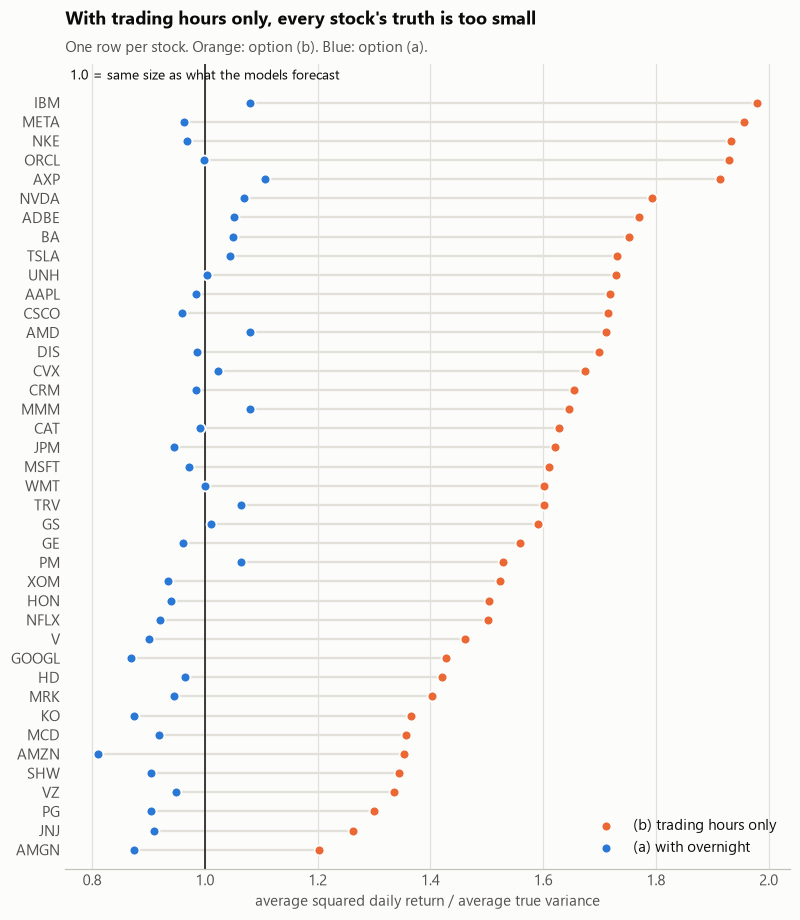

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 9.5))
y = np.arange(len(ratio))
ax.hlines(y, ratio["(a) with overnight"], ratio["(b) trading hours only"], color=GRID, lw=1.5, zorder=1)
ax.scatter(ratio["(b) trading hours only"], y, s=42, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="(b) trading hours only")
ax.scatter(ratio["(a) with overnight"], y, s=42, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="(a) with overnight")
ax.axvline(1.0, color=INK, lw=1)
ax.text(1.0, len(ratio) + 0.2, "1.0 = same size as what the models forecast", color=INK, fontsize=9, ha="center")
ax.set_yticks(y, ratio.index)
ax.set_ylim(-1, len(ratio) + 1)
ax.set_xlabel("average squared daily return / average true variance", color=MUTED)
tidy(ax, "With trading hours only, every stock's truth is too small",
     "One row per stock. Orange: option (b). Blue: option (a).")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, labelcolor=INK)
plt.show()

**What to look for.** Under (b) every orange dot is to the right of 1: for every single stock the
real close-to-close variance is larger than this truth, by 20% to almost 100%. Under (a) the blue
dots sit around 1.

**Why it matters for your question.** Your thesis asks whether models forecast too little variance.
Under (b), a GARCH model that is exactly right about close-to-close variance would look as if it
forecast 60% too much. You would be measuring the missing overnight hours, not the model.

### Check 2: what does option (a) cost?

The overnight part is a single squared return per day, so it is noisy. Look at one stock around a
large overnight gap. Change `SYMBOL`, `START` and `END` to look at other cases.

overnight share of the truth: typical day 12%, of the total over all days 39%
the 1% of days with the largest overnight moves carry 47% of all overnight variance
days on which overnight is more than 90% of the truth: 339 of 117,280
spread of the daily truth (standard deviation of its log): (a) 1.05   (b) 0.94


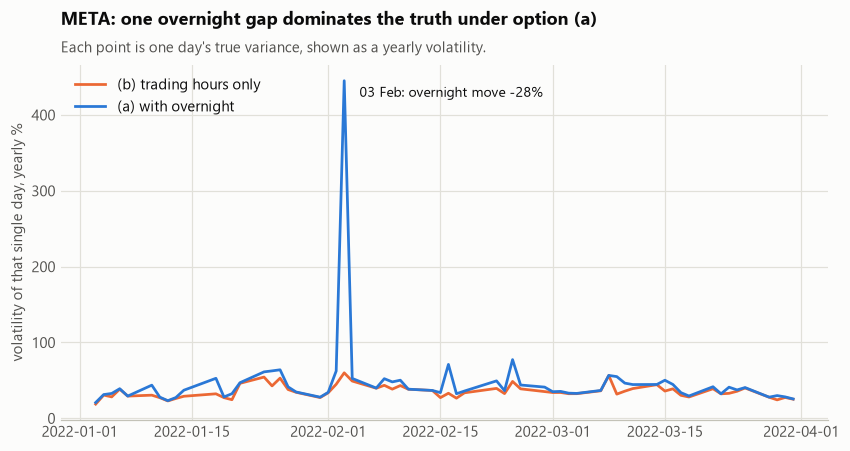

In [4]:
SYMBOL, START, END = "META", "2022-01-03", "2022-03-31"

g = panel[(panel.symbol == SYMBOL) & panel.date.between(START, END)]
to_vol = lambda variance: 100 * np.sqrt(252 * variance)      # daily variance -> yearly volatility in %

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(g.date, to_vol(g.truth_b), color=ORANGE, lw=1.8, label="(b) trading hours only")
ax.plot(g.date, to_vol(g.truth_a), color=BLUE, lw=1.8, label="(a) with overnight")
top = g.loc[g.truth_a.idxmax()]
ax.annotate(f"{top.date:%d %b}: overnight move {100 * top.ret_overnight:+.0f}%", (top.date, to_vol(top.truth_a)),
            xytext=(10, -4), textcoords="offset points", color=INK, fontsize=9, va="top")
ax.set_ylabel("volatility of that single day, yearly %", color=MUTED)
tidy(ax, f"{SYMBOL}: one overnight gap dominates the truth under option (a)",
     "Each point is one day's true variance, shown as a yearly volatility.")
ax.legend(loc="upper left", frameon=False, labelcolor=INK)
plt.show()

share = overnight2 / panel.truth_a
print(f"overnight share of the truth: typical day {share.median():.0%}, of the total over all days {overnight2.sum() / panel.truth_a.sum():.0%}")
print(f"the 1% of days with the largest overnight moves carry {overnight2.nlargest(len(panel) // 100).sum() / overnight2.sum():.0%} of all overnight variance")
print(f"days on which overnight is more than 90% of the truth: {(share > 0.9).sum()} of {len(panel):,}")
print(f"spread of the daily truth (standard deviation of its log): (a) {np.log(panel.truth_a).std():.2f}   (b) {np.log(panel.truth_b).std():.2f}")

**What to look for.** On a normal day the overnight part is small (about a tenth of the truth).
A few days with large gaps carry almost half of it. So (a) makes the truth the right size on
average but noisier day by day, and a handful of days will weigh heavily in any average error.

### Your options for decision 2

| Option | Good | Bad |
|---|---|---|
| **(a) with overnight** | Truth and forecast cover the same hours; the size is right (ratio 0.99) | Noisier; a few gap days dominate |
| **(b) trading hours only** | Clean, precise measure | About 40% too small for every model that uses daily returns |

My recommendation is **(a)**, with the scores reported in a way that is robust to single large days
(QLIKE is; plain squared error is not). Your `config.yaml` is already set this way.

---
## Decision 3: what to do on days with earnings right after the close?

The official close is at 16:00. VOLARE's window runs to 16:05. When a company reports at 16:01,
the price jump lands in those last five minutes and therefore in that day's `rv5_ss`.

### Check 3: which days are these?

They were flagged by comparing VOLARE's last price (16:05) with the official close (16:00). The
cell below recomputes that difference, so you can see the flag is reproducible.

In [5]:
# Yahoo's close is adjusted for later stock splits, VOLARE's is not. Undo the adjustment first.
split = panel["split"].fillna(0).replace(0, 1.0)
later_splits = split.groupby(panel.symbol).transform(lambda s: s[::-1].cumprod()[::-1].shift(-1).fillna(1.0))
panel["after_hours"] = np.log(panel.volare_close) - np.log(panel.close * later_splits)    # move 16:00 -> 16:05
panel["next_overnight"] = panel.groupby("symbol")["ret_overnight"].shift(-1)              # close -> next open

flag = panel.earnings_afterclose
print(f"flagged days: {flag.sum()}   |   days where the two closes differ by more than 1%: {(panel.after_hours.abs() > 0.01).sum()}")
print(f"largest difference on a day that is not flagged: {panel.after_hours[~flag].abs().max():.2%}")
print(f"typical move in those five minutes on a flagged day: {panel.after_hours[flag].abs().median():.1%}\n")

biggest = panel[flag].assign(size=panel.after_hours.abs()).nlargest(10, "size")
show = biggest[["symbol", "date"]].assign(**{"move 16:00-16:05": (100 * biggest.after_hours).round(1).astype(str) + "%",
                                             "next overnight move": (100 * biggest.next_overnight).round(1).astype(str) + "%"})
print("the ten largest (check a few against the company's earnings dates):")
print(show.to_string(index=False))

flagged days: 459   |   days where the two closes differ by more than 1%: 459
largest difference on a day that is not flagged: 1.00%
typical move in those five minutes on a flagged day: 2.0%

the ten largest (check a few against the company's earnings dates):
symbol       date move 16:00-16:05 next overnight move
  NFLX 2022-04-19           -20.2%              -35.2%
  AMZN 2022-10-27           -18.5%              -12.5%
  NFLX 2015-10-14           -14.9%               -6.0%
  AMZN 2022-02-03            14.2%               11.4%
  NFLX 2016-07-18           -13.9%              -14.6%
  NFLX 2018-10-16            13.7%                8.8%
  NFLX 2020-07-16           -13.4%               -6.4%
  AMZN 2016-01-28           -12.6%              -10.5%
  NFLX 2021-04-20           -12.5%               -7.9%
   CRM 2024-05-29           -11.9%              -19.5%


**What to look for.** The two counts agree, so the flag is exactly "the two closes differ by more
than 1%". The dates in the list should be earnings days you can look up.

### Check 4: how much does the jump distort that day, and which measure removes it?

For every flagged day, take the days from 5 before to 5 after and express each measure relative to
the stock's own normal level (its median). 1 means a normal day.

- `rv5_ss`: the standard measure, includes jumps
- `bv5_ss`: bipower variation, the alternative named in the decisions log
- `medrv5`: median realised variance, built to ignore a single jump

                            rv5_ss  bv5_ss  medrv5
days from the announcement                        
-5                            1.35    1.29    1.31
-4                            1.34    1.34    1.33
-3                            1.41    1.44    1.48
-2                            1.51    1.50    1.51
-1                            1.47    1.46    1.53
0                             6.04    3.50    1.75
1                             3.16    3.02    3.09
2                             2.05    2.07    2.05
3                             1.69    1.63    1.72
4                             1.56    1.52    1.64
5                             1.58    1.57    1.57


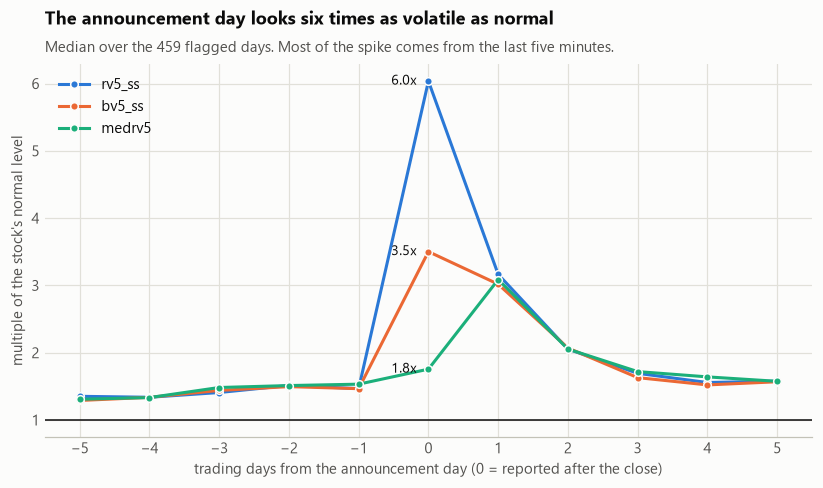

In [6]:
measures = {"rv5_ss": BLUE, "bv5_ss": ORANGE, "medrv5": AQUA}
relative = panel[list(measures)] / panel.groupby("symbol")[list(measures)].transform("median")
days = range(-5, 6)
around = pd.DataFrame({k: relative.groupby(panel.symbol).shift(-k)[flag].median() for k in days}).T
around.index.name = "days from the announcement"

fig, ax = plt.subplots(figsize=(9, 4.4))
for name, colour in measures.items():
    ax.plot(around.index, around[name], color=colour, lw=2, marker="o", ms=5, markeredgecolor=SURFACE, label=name)
    ax.annotate(f"{around.loc[0, name]:.1f}x", (0, around.loc[0, name]), xytext=(-8, 0), textcoords="offset points",
                color=INK, fontsize=9, ha="right", va="center")
ax.axhline(1.0, color=INK, lw=1)
ax.set_xticks(list(days))
ax.set_xlabel("trading days from the announcement day (0 = reported after the close)", color=MUTED)
ax.set_ylabel("multiple of the stock's normal level", color=MUTED)
tidy(ax, "The announcement day looks six times as volatile as normal",
     "Median over the 459 flagged days. Most of the spike comes from the last five minutes.")
ax.legend(loc="upper left", frameon=False, labelcolor=INK)
plt.show()
print(around.round(2).to_string())

**What to look for.** Day 0 is the day the market was open *before* the news. `rv5_ss` shows it at
six times normal. `medrv5` shows under two times, in line with the days just before it (about 1.5
times, traders waiting for results). `bv5_ss` sits in between, so it does not fully remove the
jump, although the decisions log says it is unaffected. Day +1 is high in all three: that is the real
reaction, during trading hours, and nobody wants to remove it.

### Check 5: is the jump counted twice once overnight returns are added?

The overnight return runs from the official 16:00 close to the next open. So it already contains
whatever happened between 16:00 and 16:05. If that is true, the five-minute move on day 0 and the
overnight move into day +1 should point the same way and be related.

same direction on 75% of the flagged days


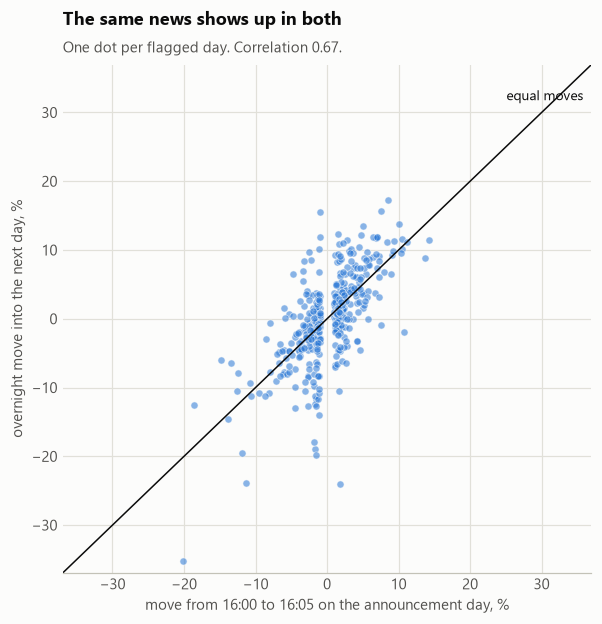

In [7]:
x, yv = 100 * panel.after_hours[flag], 100 * panel.next_overnight[flag]
ok = x.notna() & yv.notna()
corr = np.corrcoef(x[ok], yv[ok])[0, 1]

fig, ax = plt.subplots(figsize=(6.2, 6))
lim = float(np.nanmax(np.abs(np.r_[x[ok], yv[ok]]))) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=INK, lw=1)
ax.text(lim * 0.97, lim * 0.86, "equal moves", color=INK, fontsize=9, ha="right")
ax.scatter(x[ok], yv[ok], s=22, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("move from 16:00 to 16:05 on the announcement day, %", color=MUTED)
ax.set_ylabel("overnight move into the next day, %", color=MUTED)
tidy(ax, "The same news shows up in both", f"One dot per flagged day. Correlation {corr:.2f}.")
plt.show()
print(f"same direction on {(np.sign(x[ok]) == np.sign(yv[ok])).mean():.0%} of the flagged days")

**What to look for.** The dots follow the line: the five-minute move is the first part of the
overnight move. Under option (a) of decision 2 it therefore enters the truth twice, once in day 0
through `rv5_ss` and once in day +1 through the overnight return.

### Check 6: what does each choice do to the truth?

In [8]:
choices = {"keep rv5_ss (current)": panel.rv5_ss, "use bv5_ss on flagged days": panel.bv5_ss,
           "use medrv5 on flagged days": panel.medrv5}
rows = {}
for name, replacement in choices.items():
    truth = replacement.where(flag, panel.rv5_ss) + overnight2
    level = truth / truth.groupby(panel.symbol).transform("median")
    rows[name] = {"announcement day, x normal": level[flag].median(),
                  "share of all variance on those 459 days": truth[flag].sum() / truth.sum(),
                  "squared return / truth, all days": (panel.ret ** 2).mean() / truth.mean()}
print(pd.DataFrame(rows).T.round(3).to_string())
print(f"\non ordinary days medrv5 is {(panel.medrv5 / panel.rv5_ss)[~flag].median():.0%} of rv5_ss "
      f"and bv5_ss is {(panel.bv5_ss / panel.rv5_ss)[~flag].median():.0%}, so both run a little lower in general")

                            announcement day, x normal  share of all variance on those 459 days  squared return / truth, all days
keep rv5_ss (current)                            5.341                                    0.036                             0.990
use bv5_ss on flagged days                       3.039                                    0.023                             1.003
use medrv5 on flagged days                       1.682                                    0.020                             1.006

on ordinary days medrv5 is 93% of rv5_ss and bv5_ss is 93%, so both run a little lower in general


### Your options for decision 3

| Option | What happens on the 459 days | Problem |
|---|---|---|
| **Keep / flag only** (current) | The jump stays in day 0 | Counted twice under decision 2(a) |
| **Use `bv5_ss`** | Part of the jump is removed | Still far above normal on day 0 |
| **Use `medrv5`** | The jump is removed; day 0 is under twice normal | Needs a new option in the code |

My recommendation is **`medrv5` on the flagged days**, if you choose (a) for decision 2. If you
choose (b), keeping the jump is consistent, because the 16:05 window is then your definition of
the day.

The choice touches 459 of 117,280 rows, so the averages barely move. It matters because these are
the largest values in the data, and tests of "too little variance" are driven by the largest values.

---
## Recording your decision

| Decision | Where | Values |
|---|---|---|
| 2 | `config.yaml`, `target: add_overnight` | `true` = (a), `false` = (b) |
| 3 | `config.yaml`, `target: earnings_days` | `keep`, `bv5`, `flag_only`; `medrv5` does not exist yet |

After changing a value: rebuild the panel (`python -m thesis.data.build_panel`), then set the two
entries in `DECISIONS.md` to "decided" with the date and one sentence of why.